# The exposure of one swap: Hull-White paths, EE, PFE and netting

- **Level:** 1, Fundamentals
- **Prerequisites:** topics 06 and 07 of the index (portfolio capital and market risk), or none if you read the code
- **Reading time:** about 40 minutes

**Question:** If the counterparty of a 10-year payer swap defaulted at some future date, how much would it owe the bank on average and in a bad case, and how much of that exposure disappears when the swap is netted with three others?

## Objectives

By the end of this notebook you can:

- say what a one-factor short-rate model is, and rebuild the one Contraste uses (Hull-White, fitted to today's curve) from the committed curve and calibration;
- value an interest-rate swap on every simulated path and every date, and read the cloud of values as a distribution;
- compute the expected exposure (EE), the potential future exposure (PFE), the expected positive exposure (EPE) and its effective version (EEPE), each from its definition;
- show why netting is taken on the sum of the values and not on the sum of the positive parts, and measure the netting benefit;
- read an exposure in dollars: its peak, the year it occurs, and how much of it netting four swaps removes.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.ccr import exposure as ex
from riskvalidation.ccr import hw1f
from riskvalidation.ccr import swaps as sw

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Data

The data is case C12 (counterparty credit risk), as Contraste commits it. The curve is the US Treasury par yield curve of 2025-09-30 (licence class `mirror-allowed`, https://home.treasury.gov/resource-center/data-chart-center/interest-rates/), turned into continuously compounded zero rates. The swap is **synthetic**: a 10-year payer of 10 million USD whose fixed rate is the par yield at its maturity, rounded to 10 bp. The model parameters `a` and `sigma` were estimated on 35 years of the 3-month Treasury rate, using only data before the curve date.

- **Files read:** `data/derived/C12/single-swap.json` (one swap, key `outputs`) and `data/derived/C12/netting-set.json` (the same curve with four swaps). Both are documents of the schema `contraste.case/v1`.
- **Truth status:** `synthetic-calibrated`. The market inputs are real, the trades are conventions of the case, and each carries the label `convention`.
- **Why four swaps for one:** the simulation is shared by all the variants of C12, and the random draws depend on the shape of the time grid. To reproduce the bake we rebuild the grid it used, which holds the reset dates of the four swaps.

The next cell loads both documents and prints the curve, the calibration and the trade.

In [2]:
# Load the two committed documents of C12 (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C12"
single = json.loads((derived / "single-swap.json").read_text(encoding="utf-8"))
netting = json.loads((derived / "netting-set.json").read_text(encoding="utf-8"))
out = single["outputs"]
cal = out["calibration_used"]
trade = out["book"]["trades"][0]

print("curve date:", out["curve"]["curve_date"], "|", out["curve"]["source"])
for point in out["curve"]["points"][::3]:
    print(f"  tenor {point['tenor_years']:8.4f} y | par yield {point['par_yield']:.4f}"
          f" | zero rate {point['zero_rate']:.6f}")
print("calibration: a =", round(cal["a"], 6), "| sigma =", round(cal["sigma"], 6),
      "| observations:", cal["n_obs"], "|", cal["sample_start"], "to", cal["sample_end"])
side = "payer" if trade["side"] == "payer" else "receiver"
print("trade:", trade["trade_id"], side, trade["notional"]["amount"], trade["notional"]["currency"],
      "| fixed rate", trade["fixed_rate"], "| maturity", trade["maturity_years"], "y")

curve date: 2025-09-30 | US Treasury daily par yield curve (home.treasury.gov)
  tenor   0.0833 y | par yield 0.0420 | zero rate 0.041927
  tenor   0.3333 y | par yield 0.0398 | zero rate 0.039538
  tenor   2.0000 y | par yield 0.0360 | zero rate 0.035657
  tenor   7.0000 y | par yield 0.0393 | zero rate 0.039180
  tenor  30.0000 y | par yield 0.0473 | zero rate 0.048499
calibration: a = 0.167466 | sigma = 0.008798 | observations: 8939 | 1990-01-02 to 2025-09-29
trade: SW-1 payer 10000000.0 USD | fixed rate 0.042 | maturity 10.0 y


## Method

### Step 1: the curve and the model

The short rate of the one-factor Hull-White model is the sum of a deterministic part and a mean-reverting state (Hull and White, 1990; Brigo et al., 2008):

$$r_t = \varphi(t) + x_t, \qquad dx_t = -a\,x_t\,dt + \sigma\,dW_t, \qquad x_0 = 0$$

The deterministic part is chosen so that the model prices today's discount curve exactly:

$$\varphi(t) = f(0,t) + \tfrac12\left(\frac{\sigma\,(1 - e^{-a t})}{a}\right)^2$$

with $f(0,t)$ the instantaneous forward rate of today's curve. Bond prices are affine in the short rate, $P(t,T) = A(t,T)\,e^{-B(t,T)\,r_t}$ with $B(t,T) = (1 - e^{-a(T-t)})/a$. The engine's `curve_functions` turns the zero curve into two callables, today's discount factor $P(0,t)$ and the forward $f(0,t)$. The next cell builds them and checks the discount factors against $e^{-z t}$, and prints $\varphi$ against the forward to show the size of the convexity term.

In [3]:
# Today's discount function and forward from the zero curve, then the Hull-White fitting function phi
tenors = np.array([p["tenor_years"] for p in out["curve"]["points"]])
zeros = np.array([p["zero_rate"] for p in out["curve"]["points"]])
a, sigma = cal["a"], cal["sigma"]
p0, forward = hw1f.curve_functions(zeros, tenors)

t = np.array([1.0, 5.0, 10.0])
phi = hw1f.phi(t, a, sigma, forward)
print("t (years)                :", t)
print("P(0,t) from the engine  :", np.round(p0(t), 8))
print("exp(-z t) on the curve:", np.round(np.exp(-np.interp(t, tenors, zeros) * t), 8))
print("forward f(0,t)        :", np.round(forward(t), 6))
print("phi(t)                       :", np.round(phi, 6))
print("phi(t) - f(0,t) (convexity term):", np.round(phi - forward(t), 6))

t (years)                : [ 1.  5. 10.]
P(0,t) from the engine  : [0.96420438 0.83057003 0.65864838]
exp(-z t) on the curve: [0.96420438 0.83057003 0.65864838]
forward f(0,t)        : [0.035657 0.042256 0.04892 ]
phi(t)                       : [0.03569  0.0427   0.049831]
phi(t) - f(0,t) (convexity term): [3.30e-05 4.44e-04 9.11e-04]


### Step 2: the paths

The state $x_t$ is simulated exactly (its law does not depend on the step) with antithetic draws, so half of the paths mirror the other half and the sample mean of $x_t$ is zero. The time grid is the union of the report dates, the close-out dates of the collateralised variants (10 and 20 business days, as 14 and 28 calendar days on the 30/360 axis of the case) and the reset dates of the swaps. The next cell builds the four swaps from the netting-set document, builds that grid and simulates the short rate with the case's own number of paths and seed.

In [4]:
# The four swaps of the netting-set document, the simulation grid of the bake and the simulated short rate
named = out["named_parameters"]
report = np.array(named["time_grid_years"]["value"])
main = np.concatenate([[0.0], report])
closeouts = [14 / 360, 28 / 360]
swaps = [
    sw.Swap(tr["trade_id"], tr["notional"]["amount"], tr["fixed_rate"], tr["side"] == "payer",
            tr["start_years"], tr["maturity_years"], tr["fixed_frequency_per_year"])
    for tr in netting["outputs"]["book"]["trades"]
]
merged = np.unique(np.round(np.concatenate([main] + [main + d for d in closeouts]), 12))
grid = sw.simulation_grid(merged, swaps)
n_paths, seed = named["path_count"]["value"], named["seed"]["value"]
r = hw1f.simulate_short_rate(grid, a, sigma, forward, n_paths, seed)

k5 = int(np.searchsorted(grid, 5.0 - 1e-9))
ou_std = sigma * np.sqrt((1 - np.exp(-2 * a * 5.0)) / (2 * a))
print("report dates:", report.size, "| grid points:", grid.size,
      "| paths:", r.shape[0], "| seed:", seed)
print("largest gap between the mean of r and phi:",
      float(np.max(np.abs(r.mean(axis=0) - hw1f.phi(grid, a, sigma, forward)))))
print("std of r at 5 years, simulated:", round(float(r[:, k5].std()), 6),
      "| Ornstein-Uhlenbeck law:", round(float(ou_std), 6))

report dates: 33 | grid points: 102 | paths: 20000 | seed: 42
largest gap between the mean of r and phi: 1.9539925233402755e-14
std of r at 5 years, simulated: 0.01356 | Ornstein-Uhlenbeck law: 0.013705


The next cell draws thirty of the simulated paths of the short rate with the fitted mean and a band of two standard deviations of the state, to see the randomness that will move the swap.

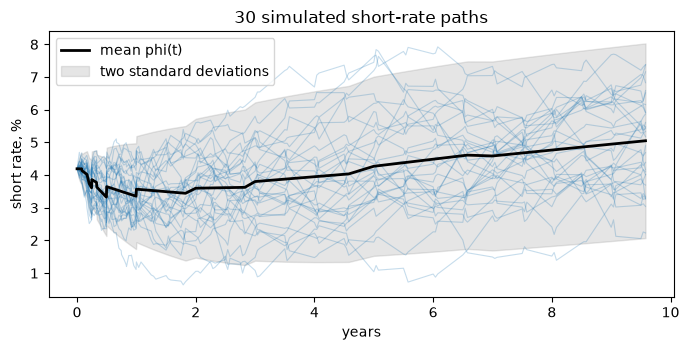

In [5]:
# Draw 30 simulated short-rate paths with the fitted mean phi(t) and a band of two standard deviations
fig, ax = plt.subplots(figsize=(7, 3.6))
spread = sigma * np.sqrt((1 - np.exp(-2 * a * grid)) / (2 * a))
mean_rate = hw1f.phi(grid, a, sigma, forward)
ax.plot(grid, 100 * r[:30].T, color="tab:blue", alpha=0.25, lw=0.8)
ax.plot(grid, 100 * mean_rate, color="black", lw=2, label="mean phi(t)")
ax.fill_between(grid, 100 * (mean_rate - 2 * spread), 100 * (mean_rate + 2 * spread), color="grey", alpha=0.2,
                label="two standard deviations")
ax.set_xlabel("years")
ax.set_ylabel("short rate, %")
ax.set_title("30 simulated short-rate paths")
ax.legend()
fig.tight_layout()
plt.show()

The figure shows thirty of the 20,000 simulated paths of the short rate. They fan out around the black curve, the fitted mean $\varphi(t)$, and the grey band marks two standard deviations of the state $x_t$. The band widens quickly and then flattens, because the mean reversion $a$ pulls every path back: this is why the model's uncertainty about a rate stops growing with the horizon. The figure does not show the swap yet, only the randomness that will move its value, and it says nothing about whether real rates behave this way (notebook 06 tests that).

### Step 3: the model reprices the curve

A model for exposure is only useful if it first reproduces today's prices. At $t=0$ the state is zero and $r_0=\varphi(0)$, so the formula $P(0,T) = A(0,T)\,e^{-B(0,T)\,\varphi(0)}$ must give back the discount factor of the curve. The engine's `bond_price` evaluates it; the next cell compares it with $P(0,T)$ at three maturities.

In [6]:
# Reprice the discount factors at t = 0 with the model and compare them with the curve
r0 = hw1f.phi(np.array(0.0), a, sigma, forward).reshape(1)
for maturity in (1.0, 5.0, 10.0):
    model = hw1f.bond_price(r0, 0.0, maturity, a, sigma, p0, forward)[0]
    curve = float(p0(np.array(maturity)))
    print(f"T = {maturity:4.1f} | model {model:.12f} | curve {curve:.12f} | difference {model - curve:.1e}")

T =  1.0 | model 0.964204378531 | curve 0.964204378531 | difference 1.1e-16
T =  5.0 | model 0.830570031476 | curve 0.830570031476 | difference 1.1e-16
T = 10.0 | model 0.658648375416 | curve 0.658648375416 | difference 0.0e+00


### Step 4: the value of the swap on every path

The swap pays the fixed rate on its fixed dates and receives the floating leg, which resets on the same schedule. On a path, the value at date $t$ to the bank (a payer swap) is the floating leg minus the fixed leg, where each remaining payment $T_i$ is discounted with the model bond price $P(t,T_i)$ at the short rate of that path and date. Between two resets the coupon already fixed is known on the path, and the engine reads it from the same path. `swap_values_on_grid` does all this for a list of swaps and returns an array of shape (swap, path, date). The fixed rate was set to the par yield, so the value at $t=0$ is small but not exactly zero (the rate was rounded to 10 bp). The next cell values the four swaps and compares the first with the par rate.

In [7]:
# Value the four swaps on every path and date, and the first one against the par rate at t = 0
values = sw.swap_values_on_grid(swaps, grid, r, a, sigma, p0, forward)
numeraire = hw1f.bank_account(grid, r, a, sigma, p0, forward)
ix = np.searchsorted(grid, report - sw.TIME_TOL)
par = sw.par_fixed_rate(10.0, 2, p0)

print("values array (swap, path, date):", values.shape)
print("par fixed rate of the 10-year swap:", round(par, 6),
      "| rate in the trade:", trade["fixed_rate"])
print("value of SW-1 at t = 0, the same on every path:",
      round(float(values[0, 0, 0]), 2))
for years in (1.0, 5.0):
    k = int(np.searchsorted(grid, years - 1e-9))
    q = np.percentile(values[0, :, k], [5, 50, 95])
    print(f"value of SW-1 at {years:.0f} y, 5% / 50% / 95%:", np.round(q, 0))

values array (swap, path, date): (4, 20000, 102)
par fixed rate of the 10-year swap: 0.041601 | rate in the trade: 0.042
value of SW-1 at t = 0, the same on every path: -32701.09
value of SW-1 at 1 y, 5% / 50% / 95%: [-533575.   25762.  553402.]
value of SW-1 at 5 y, 5% / 50% / 95%: [-475109.  234506.  894008.]


### Step 5: expected exposure, PFE and the effective measures

Exposure to the counterparty is the positive part of the value, because if the counterparty defaults the bank loses only when it is owed money. The definitions of the exposure measures (CRE53; ORE methodology) are, with $V$ the value of the netting set and $N$ the numeraire (the bank account, $N(0)=1$):

$$\mathrm{EE}(t) = \mathbb{E}\left[\frac{\max(V(t),0)}{N(t)}\right], \qquad \mathrm{PFE}_\alpha(t) = \inf\{x : F_t(x) \ge \alpha\}^+$$

The engine's `expected_exposure` returns this discounted EE and its Monte Carlo standard error. Contraste reports the undiscounted (Basel style) EE in the $t$-forward measure, which is the discounted EE divided by $P(0,t)$; that is the quantity the analytic swaption formula gives (notebook 06) and the one ORE reproduces (notebook 07). The PFE is the 95% quantile of the value, with a bootstrap error. Over the first year:

$$\mathrm{Effective\ EE}(t_k) = \max(\mathrm{Effective\ EE}(t_{k-1}),\ \mathrm{EE}(t_k)), \qquad \mathrm{EEPE} = \frac{1}{1}\sum_{t_k \le 1} \mathrm{Effective\ EE}(t_k)\,\Delta t_k$$

The next cell computes all of them for the first swap and prints the peaks and the first-year averages.

In [8]:
# EE (discounted, then forward measure), PFE, effective EE, EPE and EEPE of the single swap
p0r = p0(report)
v1 = values[0][:, ix]
ee_d, ee_d_se = ex.expected_exposure(v1, numeraire[:, ix])
ee, ee_se = ee_d / p0r, ee_d_se / p0r
pfe, pfe_se = ex.pfe(v1, named["pfe_quantile"]["value"], seed=seed, n_bootstrap=50)
eff = ex.effective_ee(ee)
epe, eepe = ex.epe(report, ee), ex.effective_epe(report, eff)
k1 = np.searchsorted(report, 1.0 - 1e-9)

print("peak of EE:", round(float(ee.max()), 0), "at", float(report[ee.argmax()]), "y")
print("peak of PFE95:", round(float(pfe.max()), 0), "at", float(report[pfe.argmax()]), "y")
print("EE at 1 y:", round(float(ee[k1]), 0), "+/-", round(float(ee_se[k1]), 0))
print("EPE:", round(epe, 2), "| EEPE:", round(eepe, 2), "| Monte Carlo error of the EEPE:",
      round(out["exposure"]["eepe"]["mc_se"], 2))

peak of EE: 294524.0 at 5.0 y
peak of PFE95: 901804.0 at 4.5 y
EE at 1 y: 141414.0 +/- 1374.0
EPE: 87550.9 | EEPE: 87550.9 | Monte Carlo error of the EEPE: 570.58


The next cell draws forty paths of the value of SW-1 together with its EE and its 95% PFE.

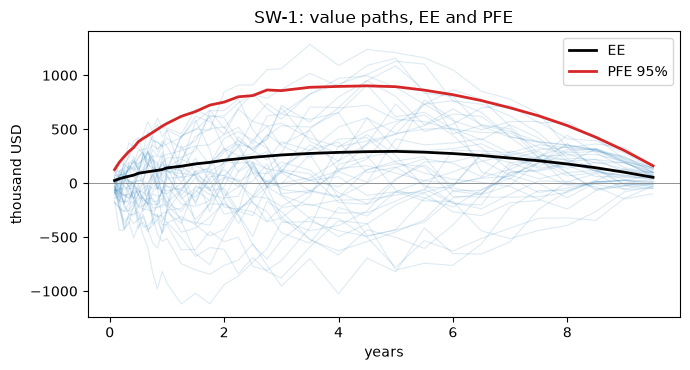

In [9]:
# Draw the value paths of SW-1 with its EE and its 95% PFE
fig, ax = plt.subplots(figsize=(7, 3.8))
for path in v1[:40]:
    ax.plot(report, path / 1e3, color="tab:blue", alpha=0.15, lw=0.8)
ax.plot(report, ee / 1e3, color="black", lw=2, label="EE")
ax.plot(report, pfe / 1e3, color="tab:red", lw=2, label="PFE 95%")
ax.axhline(0, color="grey", lw=0.6)
ax.set_xlabel("years")
ax.set_ylabel("thousand USD")
ax.set_title("SW-1: value paths, EE and PFE")
ax.legend()
fig.tight_layout()
plt.show()

The blue lines are forty paths of the swap's value, the black curve is the EE and the red curve the 95% PFE. The value fans out as the horizon grows and shrinks again as the swap amortises towards maturity, so both measures rise, peak and fall to zero. The EE sits far below the PFE because it averages the positive parts, most of which are small, while the PFE reads the tail. What the figure does not show is the loss: exposure is what the counterparty would owe if it defaulted on that date, before any recovery, and the probability of that default enters only with the CVA (notebook 03).

### Step 6: netting

A netting agreement lets the bank offset the values of all the trades with one counterparty at default, so the exposure is the positive part of the **sum** of the values, not the sum of the positive parts. Because $\max(a+b,0) \le \max(a,0) + \max(b,0)$, the netted EE is never above the sum of the single-trade EE, and the difference is the netting benefit. The engine's `net_values` adds the trades and `netting_benefit` subtracts. The next cell does it for the four swaps of the netting set and prints the benefit at three dates.

In [10]:
# EE of each swap, of their sum and of the netted set, and the netting benefit
nm = numeraire[:, ix]
ee_each = np.array([ex.expected_exposure(values[k][:, ix], nm)[0] / p0r for k in range(len(swaps))])
net = ex.net_values(values[:, :, ix])
ee_net = ex.expected_exposure(net, nm)[0] / p0r
benefit = ex.netting_benefit(ee_each, ee_net)
total = ee_each.sum(axis=0)

print("trades:", [s.trade_id for s in swaps])
print("sum of single EE minus netted EE is never negative:",
      "yes" if np.min(total - ee_net) >= -1e-9 else "no")
for years in (0.5, 1.0, 3.0):
    k = int(np.searchsorted(report, years - 1e-9))
    print(f"at {years} y | sum of EE {total[k]:10.0f} | netted EE {ee_net[k]:10.0f}"
          f" | benefit {benefit[k]:10.0f}")
print("largest benefit:", round(float(benefit.max()), 0), "at", float(report[benefit.argmax()]), "y")

trades: ['SW-1', 'SW-2', 'SW-3', 'SW-4']
sum of single EE minus netted EE is never negative: yes
at 0.5 y | sum of EE     147338 | netted EE      63261 | benefit      84077
at 1.0 y | sum of EE     209175 | netted EE     101950 | benefit     107225
at 3.0 y | sum of EE     295892 | netted EE     197976 | benefit      97916
largest benefit: 125153.0 at 1.75 y


The next cell draws the sum of the four single exposures against the netted exposure; the gap between them is the netting benefit.

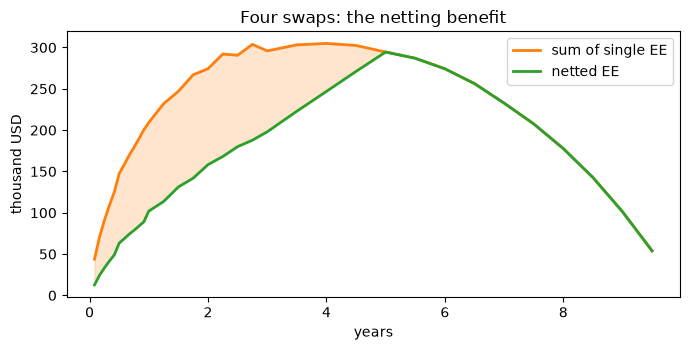

In [11]:
# Draw the sum of the four single-trade EE against the EE of the netted set
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(report, total / 1e3, color="tab:orange", lw=2, label="sum of single EE")
ax.plot(report, ee_net / 1e3, color="tab:green", lw=2, label="netted EE")
ax.fill_between(report, ee_net / 1e3, total / 1e3, color="tab:orange", alpha=0.2)
ax.set_xlabel("years")
ax.set_ylabel("thousand USD")
ax.set_title("Four swaps: the netting benefit")
ax.legend()
fig.tight_layout()
plt.show()

The orange curve adds the four exposures as if each swap were settled alone, the green curve nets the values first, and the shaded gap is the netting benefit. The gap opens early, because swaps that pay in opposite directions cancel on most paths, and it narrows at long horizons, where only the longest swap is still alive and there is little left to net. Read it as a statement about this book: the four trades were set up by the case with offsetting directions, and a book of same-direction swaps would show a much thinner band.

## Results

**Answer:** The 10-year payer swap peaks at an expected exposure of 294,524 USD at 5 years and at a 95% potential future exposure of 901,804 USD at 4.5 years; its average over the first year, the EEPE, is 87,551 USD. Netted with the three other swaps, the exposure at one year falls from 209,175 USD (the four single exposures added) to 101,950 USD, a benefit of 107,225 USD, more than half of the sum.

- **The model prices the curve.** The model bond prices equal the curve's discount factors to 1e-16, the sample mean of the simulated short rate equals $\varphi(t)$ to 2e-14, and the spread of $r$ at 5 years (0.01356) is close to the Ornstein-Uhlenbeck value (0.013705): the gap is of the order of the Monte Carlo error of 20,000 antithetic paths. The convexity term $\varphi(t) - f(0,t)$ is small at short horizons and grows to about 9 bp at 10 years.
- **One swap.** The 10-year payer pays 4.20% against a par rate of 4.160%, so it starts below zero, at -32,701 USD. Its EE rises as the value fans out and falls to zero at maturity because the swap amortises. The 95% PFE peaks earlier and higher: the PFE answers a tail question and the EE an average one.
- **The effective measures.** The EE grows over the first year, so the effective EE equals the EE there and the EPE equals the EEPE (87,551 USD, Monte Carlo error 571). They would differ for a profile that falls and rises again.
- **Netting.** At 1 year the four single EE add up to 209,175 USD and the netted EE is 101,950 USD. The benefit peaks at 125,153 USD at 1.75 years. The sum of the single EE is never below the netted EE, as the inequality on the positive part requires.

What this notebook does not show: how a collateral agreement and a margin period of risk change the exposure (notebook 02), what the exposure costs in CVA (notebook 03), or whether the model deserves trust (notebooks 06 to 08).

## Summary

- A one-factor Hull-White model, fitted to today's curve and to 35 years of the short rate, simulates the future rates; the swap is valued on every path and date with the model's own bond prices.
- EE is the average positive value, PFE a high quantile of it, EPE and EEPE their first-year time averages; Contraste reports them undiscounted, in the $t$-forward measure.
- Netting acts on the sum of the values, so the netted EE is at most the sum of the single EE; here the benefit is more than half of the sum at one year.
- The Monte Carlo error is small next to the effects read here: 571 USD on an EEPE of 87,551 USD.

**What to try next.** Change `seed` or `n_paths` in the simulation cell and watch the Monte Carlo errors move; value only SW-2 and SW-3 and see how much netting two offsetting swaps give. Then continue with notebook 02.

## References

- BCBS, Basel Framework, CRE53 Internal model method for counterparty credit risk (in force 2023-01-01, published 2020-06-05). https://www.bis.org/basel_framework/chapter/CRE/53.htm?inforce=20230101&published=20200605
- Brigo, D., Dalessandro, A., Neugebauer, M. and Triki, F. (2008), A stochastic processes toolkit for risk management, arXiv 0812.4210. https://arxiv.org/abs/0812.4210
- Open Source Risk Engine, Methodology, value adjustments and margin period of risk (xva.tex at tag 1.8.17.0). https://github.com/OpenSourceRisk/Engine/blob/1.8.17.0/Docs/UserGuide/methods/xva.tex
- U.S. Department of the Treasury, Daily Treasury Par Yield Curve Rates. https://home.treasury.gov/resource-center/data-chart-center/interest-rates/